In [67]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
from itertools import combinations, permutations

1.a

In [68]:
def configuration_model(degrees, seed=None):
    '''
    build a configuration graph from a degree sequence of non-negative integers
    take a node and give it stubs equal to its degree
    then randomly pair up the stubs to form edges
    return error for negative or non-integer degrees, or if the sum of degrees is odd
    make it reproducible with a seed for the random number generator
    '''
    if any(not isinstance(k, (int, np.integer)) or k < 0 for k in degrees):
        raise ValueError("Degrees must be non-negative integers.")
    if sum(degrees) % 2 != 0:
        raise ValueError("The sum of the degree sequence must be even.")
    rng = np.random.default_rng(seed)
    # node i appears k_i times in the stub list
    stubs = np.repeat(np.arange(len(degrees)), degrees)
    rng.shuffle(stubs)
    G = nx.MultiGraph()
    G.add_nodes_from(range(len(degrees)))
    # consecutive pairs of the shuffled stubs are the edges
    G.add_edges_from(stubs.reshape(-1, 2).tolist())
    return G

Let's test it a randomly generated degree sequence, with `seed=10` for reproducibility and visualize. Self-loops count twice toward a node's degree in a `MultiGraph`, so the output degrees should match the input exactly even if the graph has loops or parallel edges.

MultiGraph 8 nodes 22 edges
input:  [7, 9, 3, 2, 8, 8, 5, 2]
output: [7, 9, 3, 2, 8, 8, 5, 2]
degrees match: True
self-loops: [(0, 0), (1, 1), (4, 4), (5, 5), (6, 6)]
multiple edges (>1): {(0, 4): 2, (1, 5): 3, (5, 7): 2}


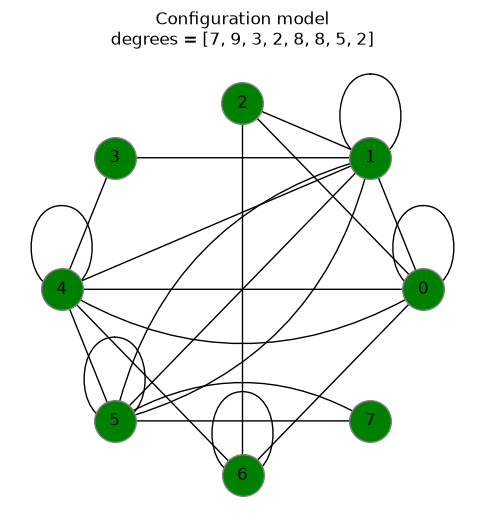

In [69]:
# random degree sequence: 8 degrees between 1 and 9, redrawn until the sum is even
rng = np.random.default_rng(10)
degrees = rng.integers(1, 10, size=8).tolist()
while sum(degrees) % 2 != 0:
    degrees = rng.integers(1, 10, size=8).tolist()

G = configuration_model(degrees, seed=10)
print(type(G).__name__, G.number_of_nodes(), "nodes", G.number_of_edges(), "edges")
print("input: ", degrees)
print("output:", [G.degree(i) for i in range(len(degrees))])
print("degrees match:", [G.degree(i) for i in range(len(degrees))] == degrees)
print("self-loops:", list(nx.selfloop_edges(G)))
print("multiple edges (>1):", {e: m for e, m in Counter(map(tuple, map(sorted, G.edges()))).items() if m > 1})

# circular layout visualization, us n.draw to see all the edges
pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(6, 6))
nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=900, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
# MultiGraph edges are (u, v, key). we should draw each parallel copy with its own curvature
# so duplicates don't sit on top of each other. alternate sides with (-1)^k and scale the curvature with k.
for u, v, k in G.edges(keys=True):
    rad = 0 if k == 0 else 0.3 * (-1) ** k * ((k + 1) // 2)
    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], arrows=True, arrowstyle="-",
                           connectionstyle=f"arc3,rad={rad}", node_size=900, ax=ax)
ax.set_title(f"Configuration model\ndegrees = {degrees}")
ax.set_axis_off()
plt.show()

Now we can test for bad inputs. An odd sum can't be paired up, and negative or non-integer degrees make no sense, so these should all raise a ValueError.

In [70]:
# odd sum, negative degree, non-integer degree
for bad in ([1, 2], [1, -1], [1.0, 1]):
    try:
        configuration_model(bad)
    except ValueError as e:
        print(bad, "->", e)

[1, 2] -> The sum of the degree sequence must be even.
[1, -1] -> Degrees must be non-negative integers.
[1.0, 1] -> Degrees must be non-negative integers.


1.b

In [71]:
def chung_lu_model(degrees, seed=None):
    '''
    build a chung lu graph from a degree sequence of non-negative integers
    for every pair of nodes i < j, add an edge independently with probability k_i k_j / 2m
    cap the probability at 1, since hubs can push k_i k_j / 2m above 1
    return error for negative or non-integer degrees
    make it reproducible with a seed for the random number generator
    '''
    if any(not isinstance(k, (int, np.integer)) or k < 0 for k in degrees):
        raise ValueError("Degrees must be non-negative integers.")
    rng = np.random.default_rng(seed)
    # 2m is the sum of the degrees
    two_m = sum(degrees)
    G = nx.Graph()
    G.add_nodes_from(range(len(degrees)))
    # each pair is its own coin flip, and i < j so there are no self-loops or duplicate edges
    for i, j in combinations(range(len(degrees)), 2):
        if two_m > 0 and rng.random() < min(1, degrees[i] * degrees[j] / two_m):
            G.add_edge(i, j)
    return G

Let's test it on a randomly generated degree sequence, with `seed=10` for reproducibility and visualize. Each edge is an independent coin flip, so the output degrees will only be approximately the input. The output should be a simple graph, so there are no self-loops or parallel edges.

Graph 8 nodes 14 edges
input:  [7, 9, 3, 2, 8, 8, 5, 2]
output: [5, 4, 2, 2, 4, 5, 5, 1]
self-loops: []


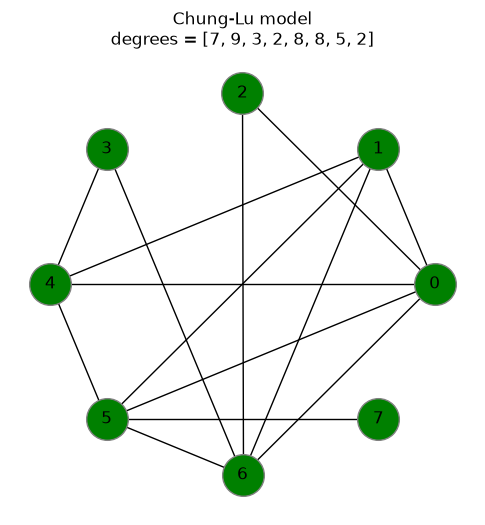

In [72]:
# random degree sequence: 8 degrees between 1 and 9
rng = np.random.default_rng(10)
degrees = rng.integers(1, 10, size=8).tolist()

G = chung_lu_model(degrees, seed=10)
print(type(G).__name__, G.number_of_nodes(), "nodes", G.number_of_edges(), "edges")
print("input: ", degrees)
print("output:", [G.degree(i) for i in range(len(degrees))])
# check for no self-loops
print("self-loops:", list(nx.selfloop_edges(G)))

# circular layout visualization
pos = nx.circular_layout(G)
fig, ax = plt.subplots(figsize=(6, 6))
nx.draw_networkx_nodes(G, pos, node_color="green", edgecolors="grey", node_size=900, ax=ax)
nx.draw_networkx_labels(G, pos, ax=ax)
# the graph is simple, so every edge can be drawn straight
nx.draw_networkx_edges(G, pos, node_size=900, ax=ax)
ax.set_title(f"Chung-Lu model\ndegrees = {degrees}")
ax.set_axis_off()
plt.show()

Now we can test for bad inputs. Negative or non-integer degrees make no sense, so these should both raise a ValueError. Unlike the configuration model, an odd sum is fine here since nothing has to be paired up.

In [73]:
# negative degree, non-integer degree
for bad in ([1, -1], [1.0, 1]):
    try:
        chung_lu_model(bad)
    except ValueError as e:
        print(bad, "->", e)

[1, -1] -> Degrees must be non-negative integers.
[1.0, 1] -> Degrees must be non-negative integers.


1.c.i

For the degree sequence from the assignment we sample $N = 1000$ graphs from each model (graph $i$ uses `seed=10+i`) and average their adjacency matrices to get $\langle A \rangle = \frac{1}{N}\sum_{i=1}^{N} A_i$. We  will make three versions: 1) the configuration model as is (a multigraph) 2) the configuration model with self-loops and duplicate edges dropped 3) Chung-Lu. In the multigraph a self-loop counts twice on the diagonal, so each row of $\langle A \rangle$ sums to that node's degree.

In [74]:
degrees_c = [8, 5, 5, 4, 3, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1]
n = len(degrees_c)
N = 1000

# running sums of the adjacency matrices for each version
A_multi = np.zeros((n, n))
A_simple = np.zeros((n, n))
A_cl = np.zeros((n, n))
for i in range(N):
    G = configuration_model(degrees_c, seed=10 + i)
    # to_numpy_array counts a self-loop once, so double the diagonal to make each row sum to the degree
    A = nx.to_numpy_array(G)
    A[np.diag_indices(n)] *= 2
    A_multi += A
    # nx.Graph merges duplicate edges, then we drop the self-loops
    G_simple = nx.Graph(G)
    G_simple.remove_edges_from(nx.selfloop_edges(G_simple))
    A_simple += nx.to_numpy_array(G_simple)
    A_cl += nx.to_numpy_array(chung_lu_model(degrees_c, seed=10 + i))

# divide by N to get the average
A_multi, A_simple, A_cl = A_multi / N, A_simple / N, A_cl / N

We set up one figure with three panels stacked vertically, all on the same color scale. Each panel gets filled in by its own cell below.

In [75]:
# same color scale for every panel, from 0 to the largest entry of the three matrices
vmax = max(A_multi.max(), A_simple.max(), A_cl.max())
fig, axes = plt.subplots(3, 1, figsize=(6, 14), layout="constrained")
# close it so it isn't shown half-empty, we display it again once all three panels are drawn
plt.close(fig)

First panel: the true configuration model. Entries can be bigger than 1 since the same pair can be joined by several edges, and the diagonal is nonzero because of the self-loops.

In [76]:
axes[0].imshow(A_multi, cmap="viridis", vmin=0, vmax=vmax)
axes[0].set_title("Configuration model (multigraph)")
axes[0].set_xticks(range(n))
axes[0].set_yticks(range(n))
axes[0].set_xlabel("node j")
axes[0].set_ylabel("node i")

Text(0, 0.5, 'node i')

Second panel: the same configuration model graphs after dropping self-loops and collapsing duplicate edges. Now every entry is the probability of at least one edge, so the diagonal is empty and nothing is above 1.

In [77]:
axes[1].imshow(A_simple, cmap="viridis", vmin=0, vmax=vmax)
axes[1].set_title("Configuration model\n(self-loops and duplicate edges dropped)")
axes[1].set_xticks(range(n))
axes[1].set_yticks(range(n))
axes[1].set_xlabel("node j")
axes[1].set_ylabel("node i")

Text(0, 0.5, 'node i')

Third panel: the Chung-Lu model. Every entry is a probability, and the cap at 1 shows up for the hub pairs.

In [78]:
axes[2].imshow(A_cl, cmap="viridis", vmin=0, vmax=vmax)
axes[2].set_title("Chung-Lu model")
axes[2].set_xticks(range(n))
axes[2].set_yticks(range(n))
axes[2].set_xlabel("node j")
axes[2].set_ylabel("node i")

Text(0, 0.5, 'node i')

Now we add a single colorbar shared by all three panels and display the figure.

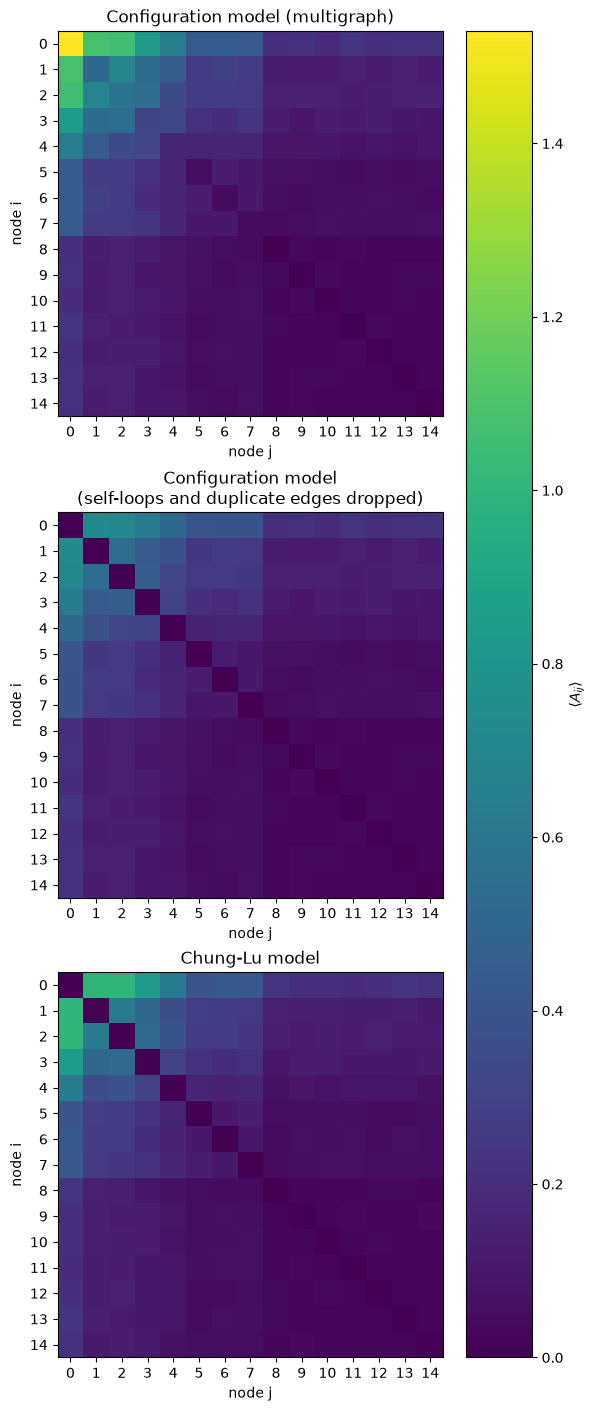

In [79]:
# one colorbar for all three panels, then display the finished figure
fig.colorbar(axes[0].images[0], ax=axes, label=r"$\langle A_{ij} \rangle$")
fig.savefig("configuration_chunglu_heatmaps.png", dpi=300)
fig

**What this figure shows.** Each panel is a heatmap of $\langle A \rangle$ for one model: entry $(i, j)$ is the average number of edges between nodes $i$ and $j$ over the 1000 sampled graphs. Nodes are sorted by degree, so node 0 is the degree-8 hub and nodes 8-14 are the degree-1 leaves. All three panels share one color scale, so the same color means the same value everywhere.

**What we were doing and why.** Both models are built from the same degree sequence, so we want to know whether they produce the same "typical" graph. The average adjacency matrix answers the first-order version of that question: for each pair of nodes, how likely (or how many) edges do we expect? If two models give the same $\langle A \rangle$ they agree on average, even if individual samples look very different. This is the setup for 1.c.ii, where we look beyond the average.

**What we see.**
- **Overall pattern is the same in all three.** The bright block is the top-left corner (hub-to-hub pairs) and the matrices fade to dark toward the leaves. Both models pair nodes in proportion to $k_i k_j$, so high-degree nodes connect to each other a lot and low-degree nodes rarely connect to each other (e.g. $\langle A_{89} \rangle \approx 0.03$ in all three, close to $k_8 k_9 / 2m = 1/38$).
- **Panel 1 (multigraph) has a bright diagonal entry at $(0,0)$ and the Chung-Lu panel has none.** The configuration model can pair two of the hub's own stubs, which is a self-loop. With 8 stubs the expected number of loops at node 0 is $\binom{8}{2} / 37 \approx 0.76$, and since a loop counts twice on the diagonal, $\langle A_{00} \rangle \approx 1.5$. That is the largest entry in the whole figure, which is why it is bright yellow. Chung-Lu only flips a coin for pairs $i < j$, so self-loops are impossible by construction and the diagonal is 0.
- **Panel 1 also has entries above 1 off the diagonal**, such as $\langle A_{01} \rangle \approx 1.09$, because the same pair can be joined by more than one edge. Every row of panel 1 sums to that node's degree exactly (node 0: 8.0), because stub matching uses every stub.
- **Panel 2 vs. panel 3 is the fair comparison.** Both are simple graphs, so each entry is a probability of an edge. They match closely for most pairs, but the hub-to-hub block differs: $\langle A_{01} \rangle \approx 0.74$ for the simplified configuration model and $1.00$ for Chung-Lu. In Chung-Lu, $p_{01} = 40/38 > 1$ gets capped at 1, so that edge is always present. In the configuration model, the hubs often get matched more than once, and the duplicates are collapsed to a single edge, so we lose edges there. This also shows up in the row sums for node 0: 8.0 in the multigraph, 5.3 in the simplified configuration model, and 6.2 in Chung-Lu. None of the simple versions keep the degree 8.

**Takeaway.** On average the models agree except at the hubs, where the multigraph's loops and multi-edges and Chung-Lu's cap on $p_{ij}$ each break the degree in a different way. But $\langle A \rangle$ only gives the mean of each entry and says nothing about how much individual graphs vary around it. For example, the leaves have expected degree about 1 in both models, but in the configuration model every leaf has exactly one edge, while in Chung-Lu a leaf has no edge at all in a sizeable fraction of graphs. That is the kind of difference we look for in 1.c.ii.

1.c.ii

The question asks for two graph metrics: one that should be about the same under both models and one that should diverge, each with a plot of its distribution across all 1000 graphs per model. Here is the metric that should **diverge**: the number of isolated nodes (degree 0) in a graph.

Why we expect it to diverge: the configuration model fixes every node's degree exactly, so nobody in this degree sequence (all degrees $\geq 1$) can end up isolated. The only exception is the simple version, where a degree-2 node can pair its two stubs together into a self-loop that we then delete. Chung-Lu only matches degrees in expectation. Seven of the 15 nodes have degree 1, and each one has no edge at all with probability roughly $e^{-37/38} \approx 0.38$, so we should see a few isolated nodes in a typical Chung-Lu graph.

We plot the CCDF, $P(X \geq x)$, where $X$ is the number of isolated nodes in one graph, for all three versions of the model from 1.c.i (same seeds as before).

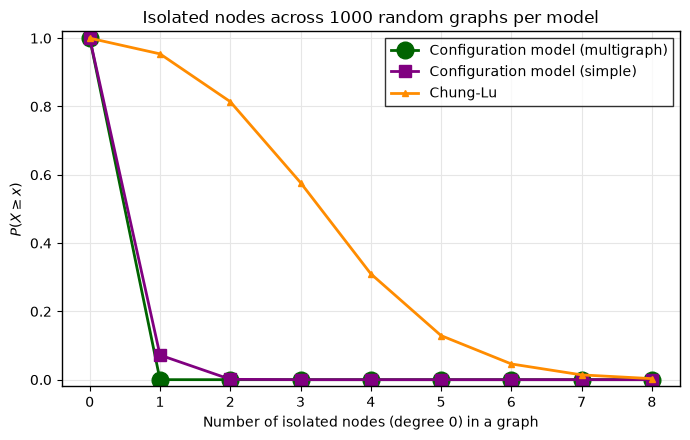

Configuration model (multigraph): mean = 0.000, P(X >= 1) = 0.000, max = 0
Configuration model (simple): mean = 0.073, P(X >= 1) = 0.072, max = 2
Chung-Lu: mean = 2.847, P(X >= 1) = 0.954, max = 8


In [80]:
def count_isolated(G):
    # nodes with degree 0. a self-loop counts twice in a MultiGraph, so loops keep a node non-isolated there
    return sum(1 for _, k in G.degree() if k == 0)

# regenerate the same 1000 graphs per model (same seeds as 1.c.i) and count isolated nodes in each
iso = {"Configuration model (multigraph)": [],
       "Configuration model (simple)": [],
       "Chung-Lu": []}
for i in range(N):
    G = configuration_model(degrees_c, seed=10 + i)
    iso["Configuration model (multigraph)"].append(count_isolated(G))
    # drop self-loops and duplicate edges, a deleted loop can leave a degree-2 node isolated
    G_simple = nx.Graph(G)
    G_simple.remove_edges_from(nx.selfloop_edges(G_simple))
    iso["Configuration model (simple)"].append(count_isolated(G_simple))
    iso["Chung-Lu"].append(count_isolated(chung_lu_model(degrees_c, seed=10 + i)))

def ccdf(values, xmax):
    # P(X >= x) at every integer x from 0 to xmax
    values = np.asarray(values)
    x = np.arange(xmax + 1)
    return x, np.array([(values >= k).mean() for k in x])

colors = {"Configuration model (multigraph)": "darkgreen",
          "Configuration model (simple)": "purple",
          "Chung-Lu": "darkorange"}
# nested marker sizes so overlapping points (everything sits at P = 1 when x = 0) stay visible
markers = {"Configuration model (multigraph)": ("o", 12),
           "Configuration model (simple)": ("s", 8),
           "Chung-Lu": ("^", 5)}

# theme_bw-ish: white panel, light gray grid, black border
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    xmax = max(max(v) for v in iso.values())
    for name, vals in iso.items():
        x, p = ccdf(vals, xmax)
        m, ms = markers[name]
        ax.plot(x, p, marker=m, markersize=ms, linewidth=2, color=colors[name], label=name)
    ax.set_xlabel("Number of isolated nodes (degree 0) in a graph")
    ax.set_ylabel(r"$P(X \geq x)$")
    ax.set_title("Isolated nodes across 1000 random graphs per model")
    ax.set_xticks(range(xmax + 1))
    ax.set_ylim(-0.02, 1.02)
    ax.legend(frameon=True, edgecolor="black", fancybox=False)
    fig.tight_layout()
    fig.savefig("isolated_nodes_ccdf.png", dpi=300)
    plt.show()

for name, vals in iso.items():
    vals = np.array(vals)
    print(f"{name}: mean = {vals.mean():.3f}, P(X >= 1) = {(vals >= 1).mean():.3f}, max = {vals.max()}")

**Reading the plot.** All three curves start at 1, since every graph has at least 0 isolated nodes. The multigraph curve (green) drops straight to 0: not one of the 1000 configuration-model multigraphs has an isolated node, because degrees are exact and nobody in the sequence has degree 0. The simple configuration model (purple) is almost the same, with isolated nodes in only about 7% of graphs (a degree-2 node whose loop got deleted), and never more than 2. Chung-Lu (orange) is completely different: 95% of graphs have at least one isolated node, the average is about 2.8, and a graph can have as many as 8. Most of these are the degree-1 nodes that never got a coin flip to come up heads.

This is the same story as the heatmaps, one level down. On average the models agree ($\langle A \rangle$ for a leaf sums to about 1 in both), but the configuration model forces every leaf to have exactly one edge, while Chung-Lu only gets one on average and so leaves it to chance.

Now the metric that should be **about the same** under both models: the number of nodes with degree exactly 4 in a graph. This is the same kind of count as before (nodes with degree $k$), just at a different $k$. For $k = 0$ the models disagree, and in the middle of the degree range we expect them to agree.

Reading the plot below: the input sequence has exactly one node of degree 4, so the configuration multigraph will always have exactly one (its degrees are exact). The two simple graphs can be above or below that, since degrees move around once duplicate edges are collapsed (configuration model) or edges are flipped independently (Chung-Lu), so what we compare is whether those two distributions look alike. We reuse the 1000 graphs per model, the CCDF helper, and the colors from the previous plot.

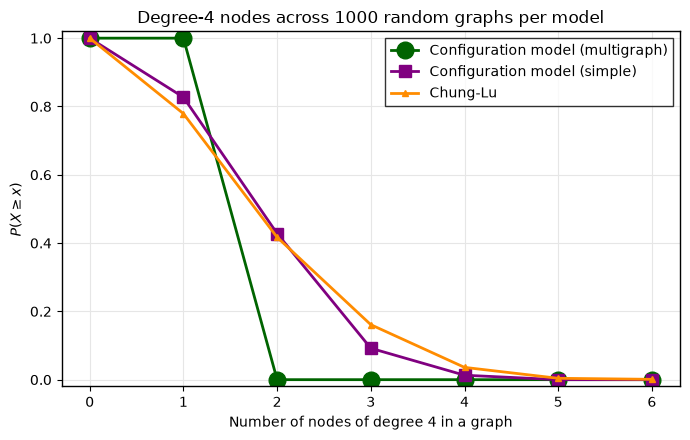

Configuration model (multigraph): mean = 1.000, sd = 0.000, max = 1
Configuration model (simple): mean = 1.360, sd = 0.901, max = 4
Chung-Lu: mean = 1.398, sd = 1.086, max = 6


In [81]:
def count_degree(G, k):
    # number of nodes with degree exactly k
    return sum(1 for _, d in G.degree() if d == k)

# regenerate the same 1000 graphs per model (same seeds as before) and count the nodes of degree 4
k4 = {"Configuration model (multigraph)": [],
      "Configuration model (simple)": [],
      "Chung-Lu": []}
for i in range(N):
    G = configuration_model(degrees_c, seed=10 + i)
    k4["Configuration model (multigraph)"].append(count_degree(G, 4))
    G_simple = nx.Graph(G)
    G_simple.remove_edges_from(nx.selfloop_edges(G_simple))
    k4["Configuration model (simple)"].append(count_degree(G_simple, 4))
    k4["Chung-Lu"].append(count_degree(chung_lu_model(degrees_c, seed=10 + i), 4))

# same theme_bw-ish style, ccdf helper, colors, and nested markers as the isolated-nodes plot
with plt.rc_context({"axes.facecolor": "white", "axes.edgecolor": "black", "axes.linewidth": 1,
                     "axes.grid": True, "grid.color": "0.9", "axes.axisbelow": True,
                     "axes.spines.top": True, "axes.spines.right": True}):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    xmax = max(max(v) for v in k4.values())
    for name, vals in k4.items():
        x, p = ccdf(vals, xmax)
        m, ms = markers[name]
        ax.plot(x, p, marker=m, markersize=ms, linewidth=2, color=colors[name], label=name)
    ax.set_xlabel("Number of nodes of degree 4 in a graph")
    ax.set_ylabel(r"$P(X \geq x)$")
    ax.set_title("Degree-4 nodes across 1000 random graphs per model")
    ax.set_xticks(range(xmax + 1))
    ax.set_ylim(-0.02, 1.02)
    ax.legend(frameon=True, edgecolor="black", fancybox=False)
    fig.tight_layout()
    fig.savefig("degree4_nodes_ccdf.png", dpi=300)
    plt.show()

for name, vals in k4.items():
    vals = np.array(vals)
    print(f"{name}: mean = {vals.mean():.3f}, sd = {vals.std():.3f}, max = {vals.max()}")

**Reading the plot.** The multigraph (green) is a point mass: every graph has exactly one degree-4 node, so its curve is 1 at $x = 0, 1$ and then drops to 0. The simple configuration model (purple) and Chung-Lu (orange) lie almost on top of each other. The averages are 1.36 and 1.40 degree-4 nodes, and the CCDFs are within a few percentage points over most of the range: about 83% vs. 78% of graphs have at least one, and about 43% vs. 42% have at least two. Chung-Lu has a slightly heavier right tail (at least three: 16% vs. 9%, and it can reach 6), which fits its larger variance, but the two are clearly the same shape, unlike the isolated-node plot where the curves were nowhere near each other.

So the models agree on how many mid-degree nodes a typical graph has, and disagree on how many nodes are cut off entirely. That fits the heatmaps: the models are close on average away from the hubs, and what separates them is how much each one lets degrees stray from the input.

(This agreement is partly specific to this degree sequence: some nodes slide down to degree 4 from higher degrees and others slide up from lower ones, and in the middle of the sequence those roughly balance.)

2.a

First, we will important ensure we understand structure of the data from the EU research email network. 

In [82]:
# directed edge list each line is "source target", no header
edges = pd.read_csv("EU Email network/email-Eu-core.txt", sep=r"\s+", header=None, names=["source", "target"])
# one department label per node: "node department"
labels = pd.read_csv("EU Email network/email-Eu-core-department-labels.txt", sep=r"\s+", header=None, names=["node", "department"])

# add every labeled node first so none can go missing, then the edges, then the department attribute
D = nx.DiGraph()
D.add_nodes_from(labels["node"])
D.add_edges_from(zip(edges["source"], edges["target"]))
nx.set_node_attributes(D, labels.set_index("node")["department"].to_dict(), "department")

Now we check what we loaded. The file should be a directed graph on 1005 nodes with one department label per node. We also will look at things that matter for community detection later, self-loops (someone emailing themselves), how much of the graph is reciprocated, and how big the departments are.

In [83]:
print(f"nodes: {D.number_of_nodes()}, directed edges: {D.number_of_edges()}")
print("rows in the edge file:", len(edges), "| duplicate rows:", edges.duplicated().sum())
print("nodes without a department:", sum("department" not in d for _, d in D.nodes(data=True)))

# self-loops, and how many of the directed edges are reciprocated (mutual ties)
n_loops = nx.number_of_selfloops(D)
n_recip = sum(1 for u, v in D.edges() if u != v and D.has_edge(v, u))
print(f"self-loops: {n_loops}")
print(f"reciprocated edges (excluding loops): {n_recip} of {D.number_of_edges() - n_loops}")
print("nodes with in-degree 0:", sum(1 for n in D if D.in_degree(n) == 0),
      "| out-degree 0:", sum(1 for n in D if D.out_degree(n) == 0))
print("weakly connected components:", nx.number_weakly_connected_components(D))

# department sizes
dept_sizes = Counter(nx.get_node_attributes(D, "department").values())
print(f"\ndepartments: {len(dept_sizes)}")
print("five largest (department: nodes):", dept_sizes.most_common(5))
print("number of singleton departments:", sum(1 for s in dept_sizes.values() if s == 1))

nodes: 1005, directed edges: 25571
rows in the edge file: 25571 | duplicate rows: 0
nodes without a department: 0
self-loops: 642
reciprocated edges (excluding loops): 17730 of 24929
nodes with in-degree 0: 14 | out-degree 0: 137
weakly connected components: 20

departments: 42
five largest (department: nodes): [(4, 109), (14, 92), (1, 65), (21, 61), (15, 55)]
number of singleton departments: 2


Since this exercise is only about community detection, we will simplify the network in a few ways to allow for specific algos to be used
1. Drop every self-loop (an email to oneself says nothing about who talks to whom, and thus nothing about communities), then drop the nodes that only had self-loops and are now isolated, since they can't belong to any community.
2. Drop edge direction, so we have an undirected graph, to assist modularity calculation.
3. Remove the duplicate edges that dropping direction creates (a mutual pair $a \to b$, $b \to a$ becomes two copies of the same edge). `nx.Graph` already keeps one edge per pair, so steps 2 and 3 happen together.

We keep the department labels on the nodes. They are the ground truth we can compare the detected communities against later, so we also save them as a `{node_id: department}` dictionary.

In [84]:
# 1) drop self-loops, then drop the nodes that only had self-loops and are now isolated
D_clean = D.copy()
D_clean.remove_edges_from(nx.selfloop_edges(D_clean))
isolated = list(nx.isolates(D_clean))
D_clean.remove_nodes_from(isolated)
print(f"after dropping self-loops: removed {n_loops} edges, then {len(isolated)} isolated nodes")

# 2) + 3) drop direction. nx.Graph keeps one edge per pair, so a mutual pair (a -> b and b -> a) collapses to one edge
G_email = nx.Graph(D_clean)
print(f"undirected graph: {G_email.number_of_nodes()} nodes, {G_email.number_of_edges()} edges")
print(f"mutual pairs collapsed into a single edge: {D_clean.number_of_edges() - G_email.number_of_edges()}")
print("connected components:", nx.number_connected_components(G_email))

# ground truth to compare against after community detection: {node_id: department}
ground_truth = nx.get_node_attributes(G_email, "department")
print("departments left:", len(set(ground_truth.values())), "; is every node still labeled:", len(ground_truth) == G_email.number_of_nodes())

after dropping self-loops: removed 642 edges, then 19 isolated nodes
undirected graph: 986 nodes, 16064 edges
mutual pairs collapsed into a single edge: 8865
connected components: 1
departments left: 42 ; is every node still labeled: True



At this point, while looking into NetworkX documentation, I realized a directed implementation of Louvain also exists, so I thought we could test and visualize both the directed version on `D_clean` and the undirected on `G_email`. We'll run both off the same seed and store the partitions to compare. 

In [85]:
def to_partition(communities):
    # list of node sets -> {node_id: community_id}
    return {node: cid for cid, comm in enumerate(communities) for node in comm}

# undirected Louvain on G_email (the simplified graph), directed Louvain on D_clean (same nodes, keeps edge direction)
# sort the communities by size so that community 0 is the largest in both
comms_und = sorted(nx.community.louvain_communities(G_email, seed=10), key=len, reverse=True)
comms_dir = sorted(nx.community.louvain_communities(D_clean, seed=10), key=len, reverse=True)
partition_und = to_partition(comms_und)
partition_dir = to_partition(comms_dir)

# modularity is computed with each graph's own definition (the directed one for D_clean), so the two are not strictly comparable
print(f"undirected Louvain on G_email: {len(comms_und)} communities, modularity = {nx.community.modularity(G_email, comms_und):.3f}")
print(f"directed Louvain on D_clean:   {len(comms_dir)} communities, modularity = {nx.community.modularity(D_clean, comms_dir):.3f}")
print("undirected community sizes:", [len(c) for c in comms_und])
print("directed community sizes:  ", [len(c) for c in comms_dir])

undirected Louvain on G_email: 8 communities, modularity = 0.413
directed Louvain on D_clean:   6 communities, modularity = 0.427
undirected community sizes: [179, 176, 141, 131, 125, 108, 94, 32]
directed community sizes:   [327, 240, 146, 116, 95, 62]


In [86]:
# louvain is randomized, so one seed can mislead. repeat both runs over 20 seeds
sweep = []
for s in range(20):
    cu = nx.community.louvain_communities(G_email, seed=s)
    cd = nx.community.louvain_communities(D_clean, seed=s)
    sweep.append({"communities (undirected)": len(cu), "communities (directed)": len(cd),
                  "modularity (undirected)": nx.community.modularity(G_email, cu),
                  "modularity (directed)": nx.community.modularity(D_clean, cd)})
pd.DataFrame(sweep).agg(["mean", "std", "min", "max"]).T.round(3)

,mean,std,min,max
communities (undirected),7.700,0.733,6.000,9.000
communities (directed),7.500,0.607,6.000,8.000
modularity (undirected),0.413,0.002,0.408,0.417
modularity (directed),0.427,0.002,0.420,0.429


The two detection outputs look slightly different when computed with a single seed, here there were more communities for the undirected Louvain. The 20-seed table above shows that iteration shows this is mostly random noise. Over 20 runs both versions find about 7.5 to 8 communities (7.7 undirected, 7.5 directed). So keeping edge direction does not change how many communities are broadly arising. Furthermore, the consistenly larger directed community sizes indicate to me that its highly likely the directed communities are encompassing the nodes of the undirected ones, and dropping directionality is probably breaking apart some communities, leading both to the higher mean and higher max number of communities found in the iteration runs. Overall, I'm going to continue with `D_clean`, the directed version of the network with self loops dropped, and isolated nodes dropeed after that. 

The directed modularity is consistently higher, but I don't think we are able to read that as the directed run being better, since the two numbers come from different modularity formulas on different graphs, and I have not looked deeper into the mathematical derivation of the directed function.

2.a

Now we can try visualize both partitions, following the class 07 examples: a spring layout, nodes colored by community with a colormap, and no node labels (there are too many nodes). Both panels share one layout, computed once on the undirected graph (same nodes as `D_clean`), so only the colors differ between them. `D_clean` has about 25k directed edges, so arrowheads would be unreadable and its edges are drawn as plain faint lines. Communities are numbered by size in each run, so color 0 is the largest community in both panels, but the same color in the two panels does not mean the same community.

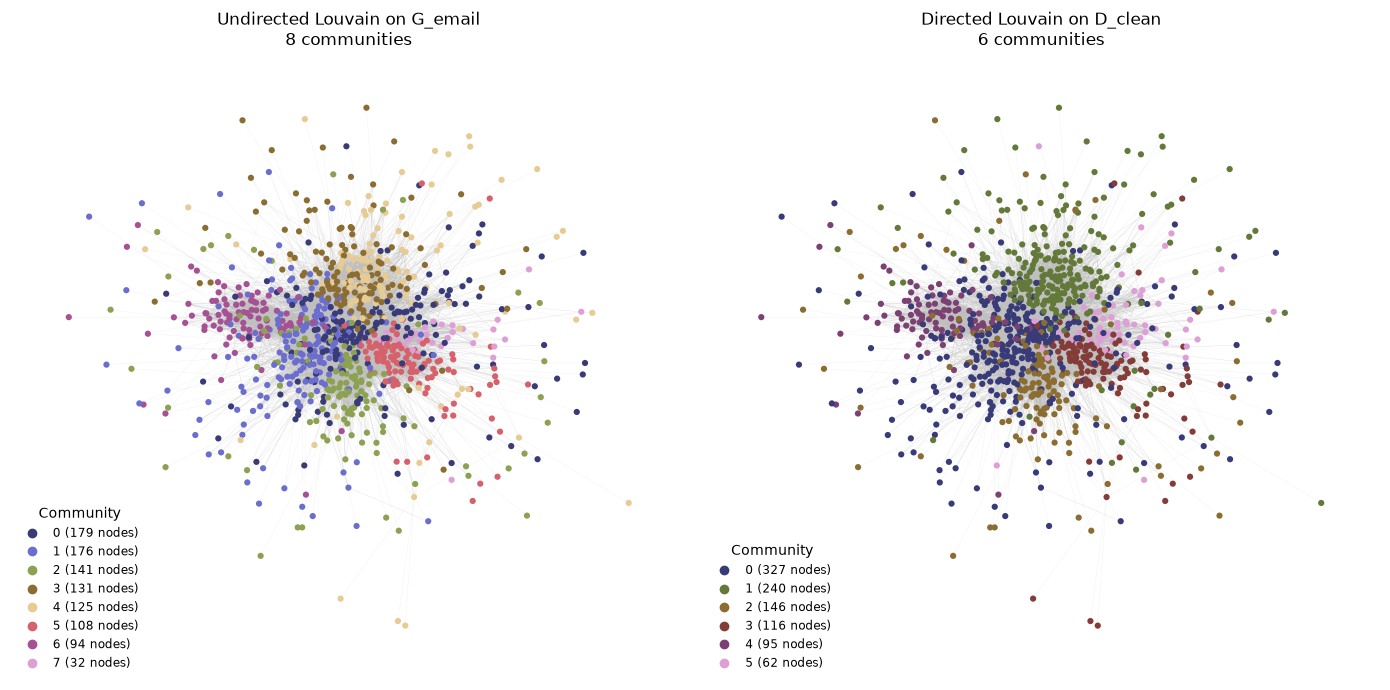

In [89]:
from matplotlib.lines import Line2D
pos_email = nx.spring_layout(G_email, seed=10)
def community_colors(partition):
    ids = np.unique(list(partition.values()))
    palette = dict(zip(ids, plt.cm.tab20b(np.linspace(0, 1, len(ids)))))
    return [palette[partition[n]] for n in D_clean.nodes()], palette
panels = [(partition_und, "Undirected Louvain on G_email"),
          (partition_dir, "Directed Louvain on D_clean")]
fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=100)
for ax, (partition, title) in zip(axes, panels):
    node_colors, palette = community_colors(partition)
    sizes = Counter(partition.values())
    # D_clean is directed, but with ~25k edges arrowheads are unreadable, so edges are drawn as plain faint lines
    nx.draw_networkx_edges(D_clean, pos_email, arrows=False, edge_color="0.75", width=0.2, alpha=0.3, ax=ax)
    nx.draw_networkx_nodes(D_clean, pos_email, node_color=node_colors, node_size=20, linewidths=0, ax=ax)
    # legend: community id (sorted by size, so 0 is the largest) and how many nodes it has
    handles = [Line2D([0], [0], marker="o", linestyle="", color=palette[c], label=f"{c} ({sizes[c]} nodes)")
               for c in sorted(palette)]
    ax.legend(handles=handles, title="Community", loc="lower left", fontsize="small", frameon=False)
    ax.set_title(f"{title}\n{len(palette)} communities", fontsize="large")
    ax.set_axis_off()
fig.tight_layout()
fig.savefig("email_communities.png", dpi=300)
plt.show()

The plain spring layout above piles most of the nodes into one hairball. Here is the same figure with a layout that uses the communities: edges inside a community pull 10 times harder than edges between communities, so each community clusters into its own region. The communities now shape the node positions, so the clustering in the picture is partly built in.  

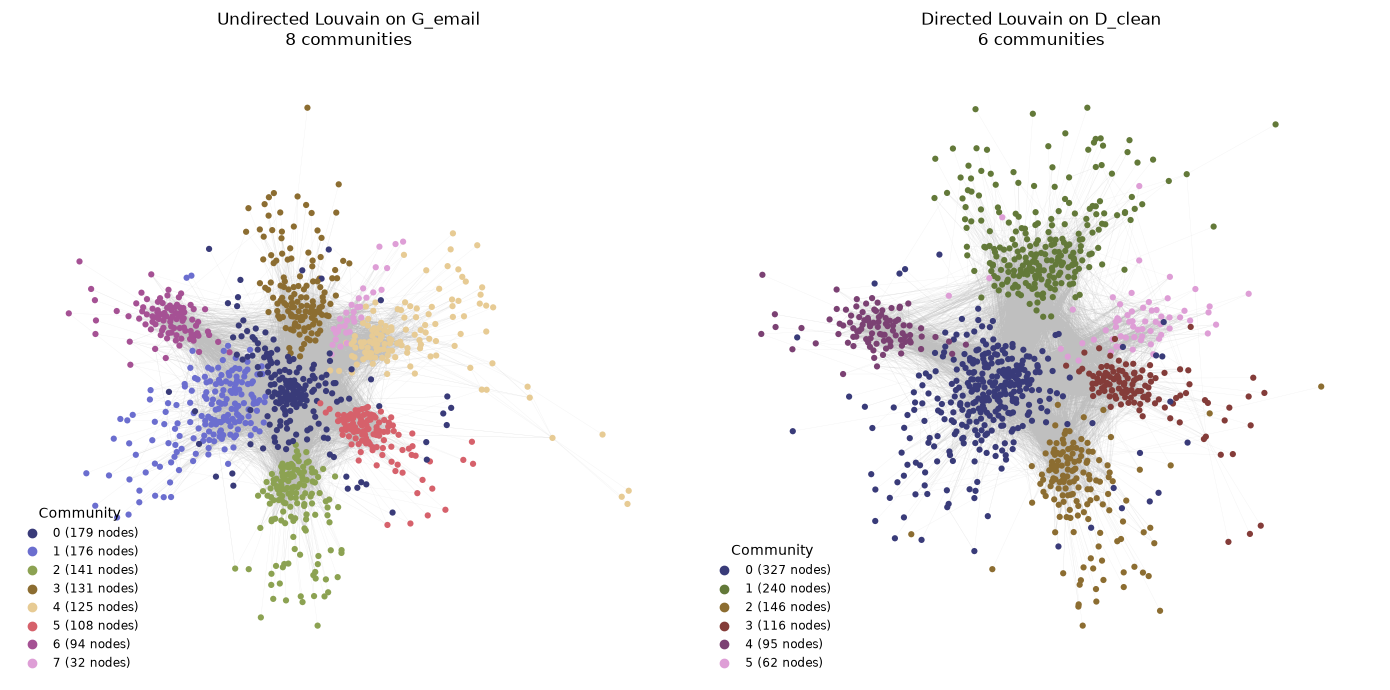

In [90]:
def weighted_layout(G, partition, intra=10, seed=10):
    # spring layout where edges inside a community pull `intra` times harder than edges between communities
    H = nx.Graph()
    H.add_nodes_from(G)
    for u, v in G.edges():
        H.add_edge(u, v, weight=intra if partition[u] == partition[v] else 1)
    return nx.spring_layout(H, weight="weight", seed=seed)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), dpi=100)
for ax, (partition, title) in zip(axes, panels):
    # each panel gets its own layout, built from its own partition (G_email has the same nodes and pairs as D_clean)
    pos_comm = weighted_layout(G_email, partition)
    node_colors, palette = community_colors(partition)
    sizes = Counter(partition.values())
    nx.draw_networkx_edges(D_clean, pos_comm, arrows=False, edge_color="0.75", width=0.2, alpha=0.25, ax=ax)
    nx.draw_networkx_nodes(D_clean, pos_comm, node_color=node_colors, node_size=20, linewidths=0, ax=ax)
    handles = [Line2D([0], [0], marker="o", linestyle="", color=palette[c], label=f"{c} ({sizes[c]} nodes)")
               for c in sorted(palette)]
    ax.legend(handles=handles, title="Community", loc="lower left", fontsize="small", frameon=False)
    ax.set_title(f"{title}\n{len(palette)} communities", fontsize="large")
    ax.set_axis_off()

fig.tight_layout()
fig.savefig("email_communities_weighted.png", dpi=300)
plt.show()

this is a little better, we can "see" the communities now, but its still too difficult to get an intuitive feel for the "shape" of the network, since there is no underlying logic to the spatial layout.